FASE 12: K=3, N=101, T=60000, 100 cadenas, semilla maestra 1907443528



s=0 (azar)  frec(0,1,2)=(0.3334, 0.3332, 0.3335)  M(1)=5.252e-05  M(2)=5.075e-05  M(3)=4.669e-05  M_max=5.776e-05 (d=13)  M(d)=0 en 0 distancias  tasa de exito: no se mide  turnos con opcion vacia: no se cuentan  [33 s]


  COMPROBACION agentes al azar vs Fase 8: M(d) de las 100 cadenas identica al CSV Fase8_Md_agentes_al_azar_K3_N101_T60000_todas_las_cadenas.csv: True


m=1, s=1    frec(0,1,2)=(0.4190, 0.3277, 0.2533)  M(1)=4.053e-01  M(2)=3.695e-01  M(3)=3.440e-01  M_max=4.053e-01 (d=1)  M(d)=0 en 0 distancias  tasa de exito=0.2836  turnos con opcion vacia=0 de 6000000  [46 s]


m=2, s=1    frec(0,1,2)=(0.3039, 0.3796, 0.3165)  M(1)=4.697e-01  M(2)=5.422e-01  M(3)=5.350e-01  M_max=6.092e-01 (d=60)  M(d)=0 en 0 distancias  tasa de exito=0.2859  turnos con opcion vacia=0 de 6000000  [47 s]


m=2, s=2    frec(0,1,2)=(0.3333, 0.3333, 0.3333)  M(1)=7.939e-09  M(2)=1.068e-08  M(3)=1.828e-02  M_max=1.828e-02 (d=3)  M(d)=0 en 0 distancias  tasa de exito=0.2761  turnos con opcion vacia=0 de 6000000  [49 s]


... (15 outputs left out)

  m = 2, s = 2                     d_desde_m_mas_1  n= 98  A=  -4.0139  B=   2.0067  C=  1.0232  alfa=   4.3002  R2=0.8301  RMSE=0.1761  convergentes=30/30  aviso_limite=0  aviso_debil=0


  m = 2, s = 2                     recta (todos los d): pendiente=0.0080  R2=0.0000



Guardado: csv\Fase12_ajustes_hill_N101_T60000.csv

Graficas:


  Guardado: graficas\Fase12_Md_hill_N101_m1_s0_T60000.png


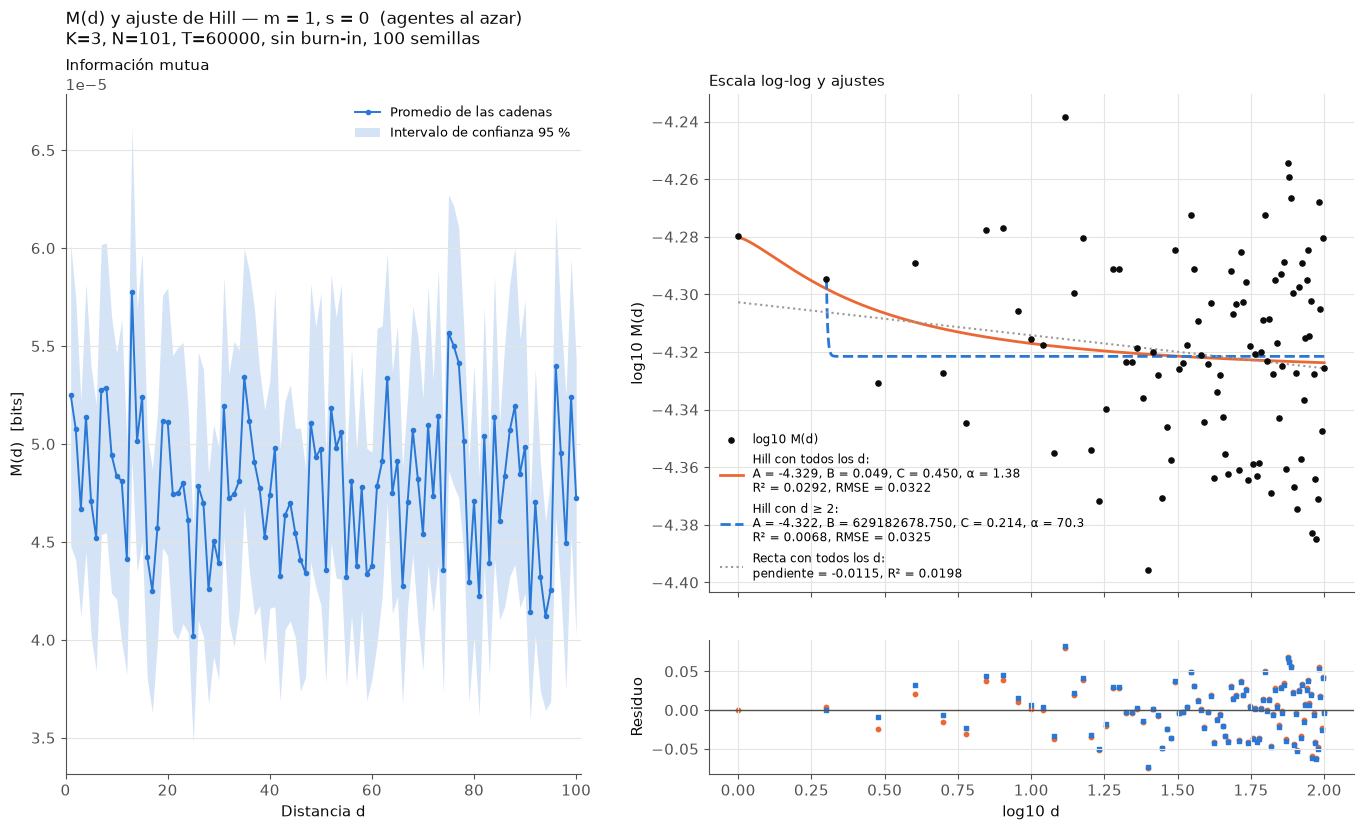

  Guardado: graficas\Fase12_Md_hill_N101_m1_s1_T60000.png


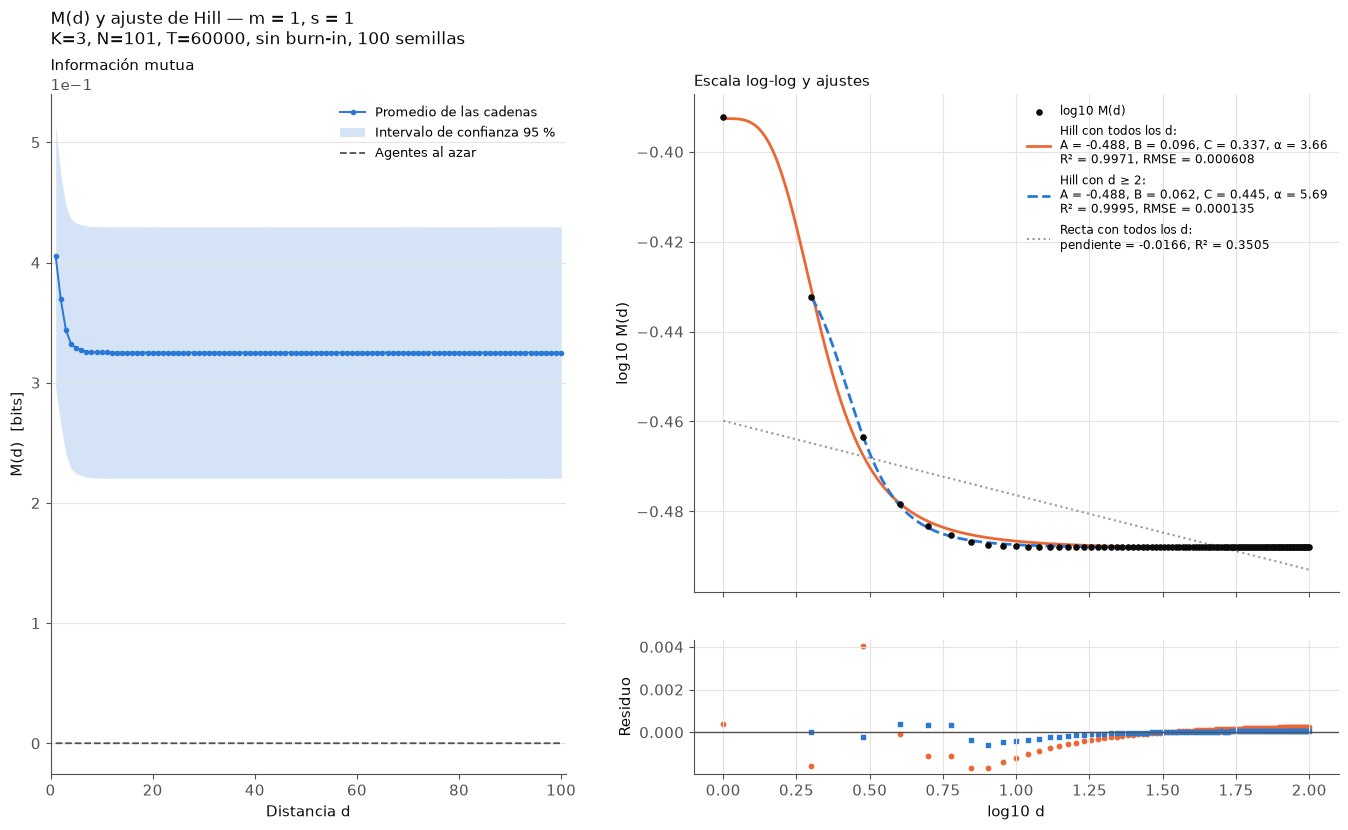

  Guardado: graficas\Fase12_Md_hill_N101_m2_s0_T60000.png


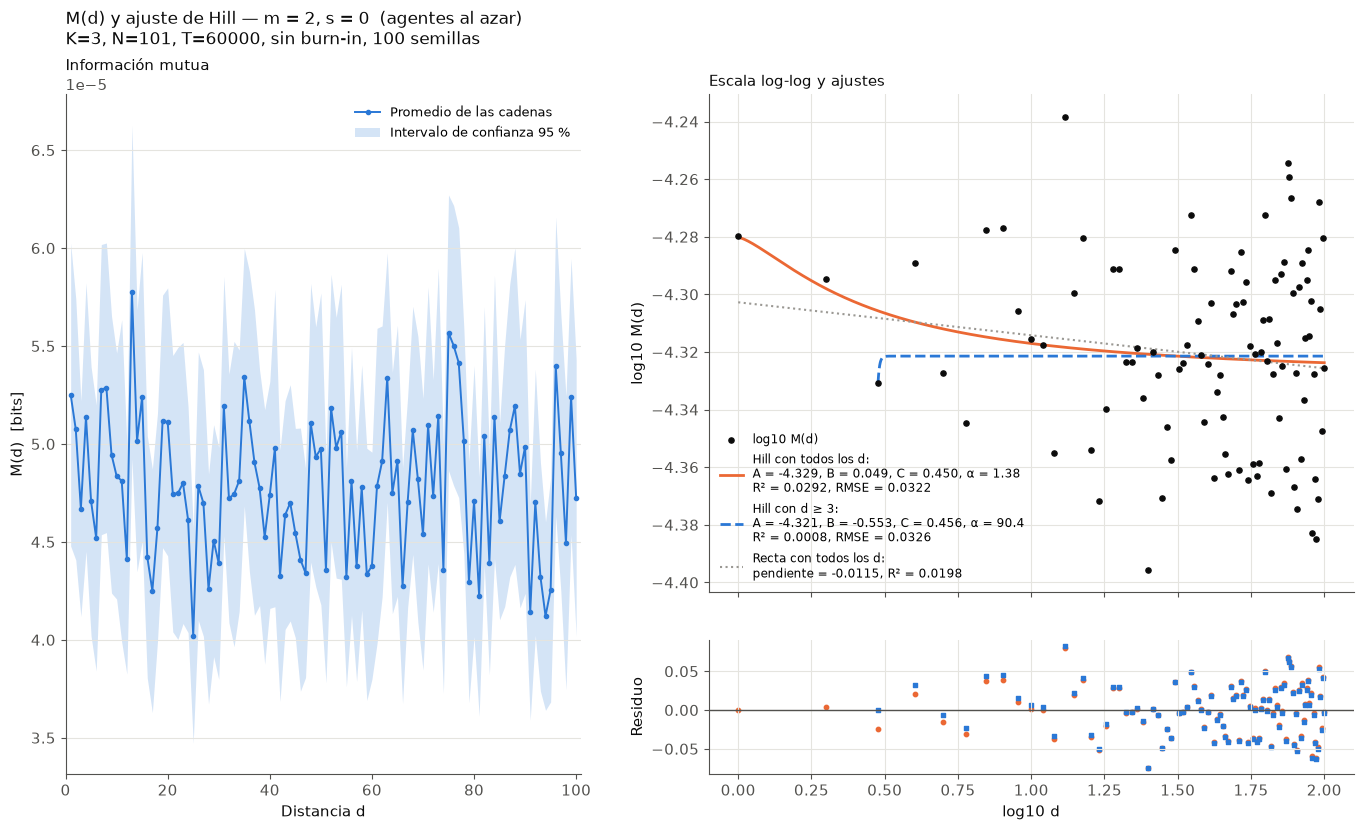

  Guardado: graficas\Fase12_Md_hill_N101_m2_s1_T60000.png


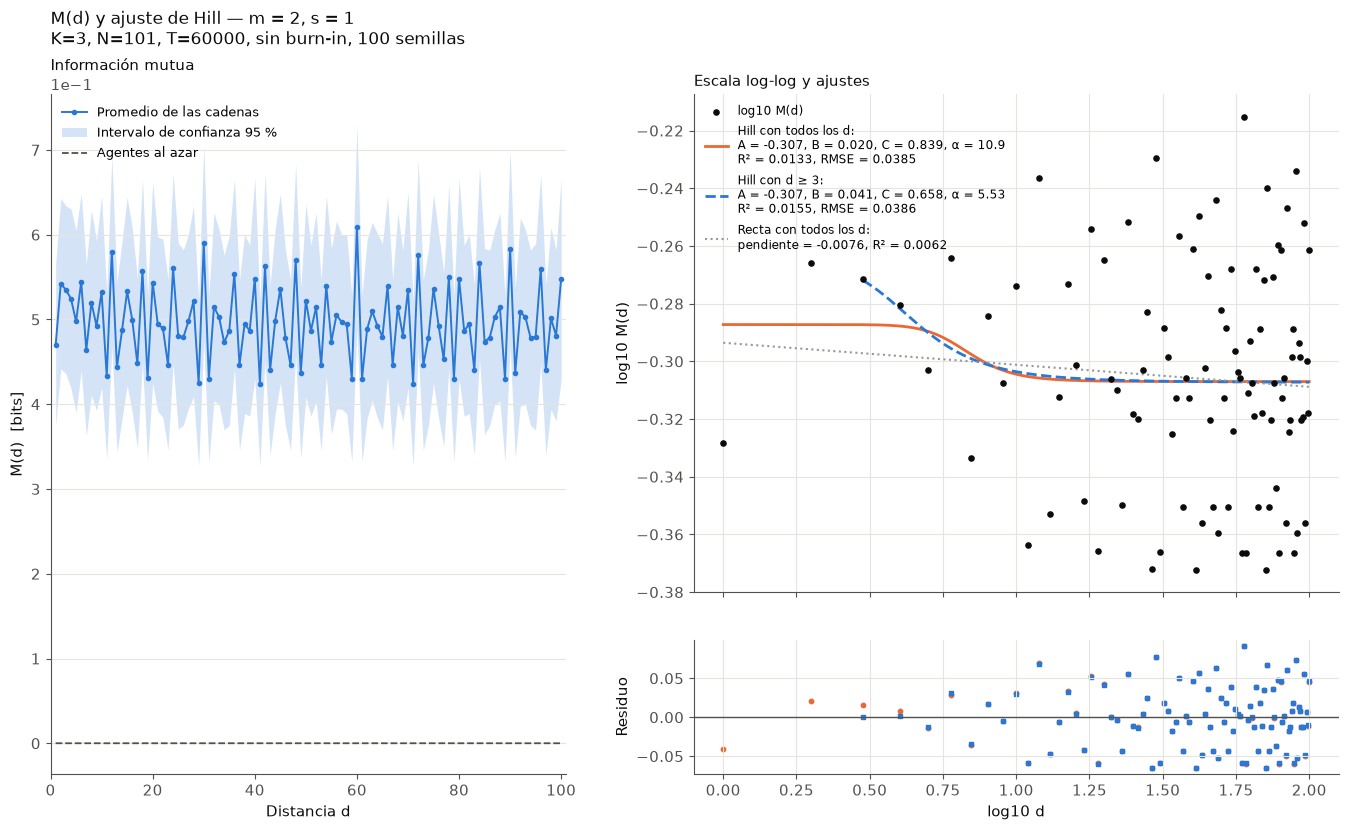

  Guardado: graficas\Fase12_Md_hill_N101_m2_s2_T60000.png


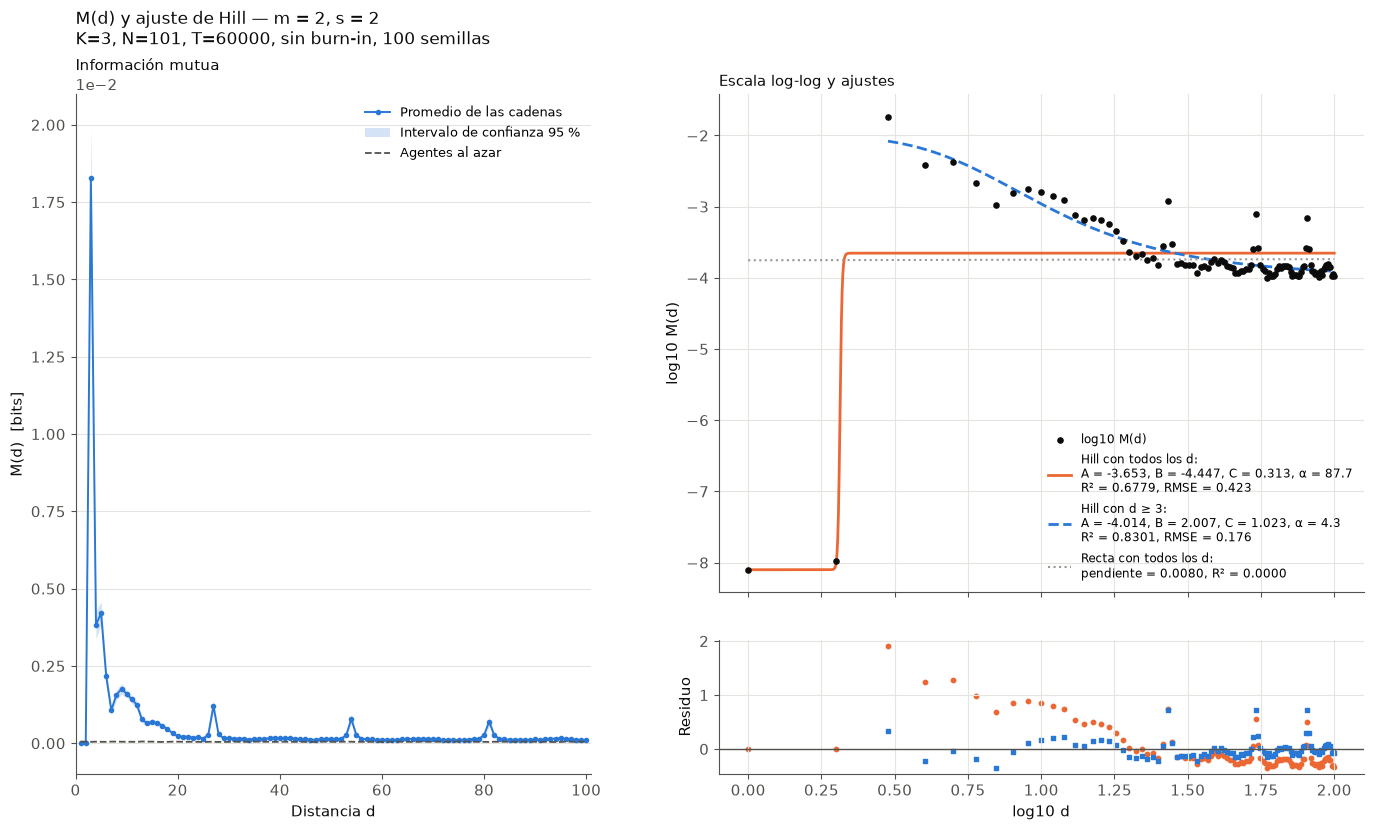

  Guardado: graficas\Fase12_comparacion_hill_N101_T60000.png


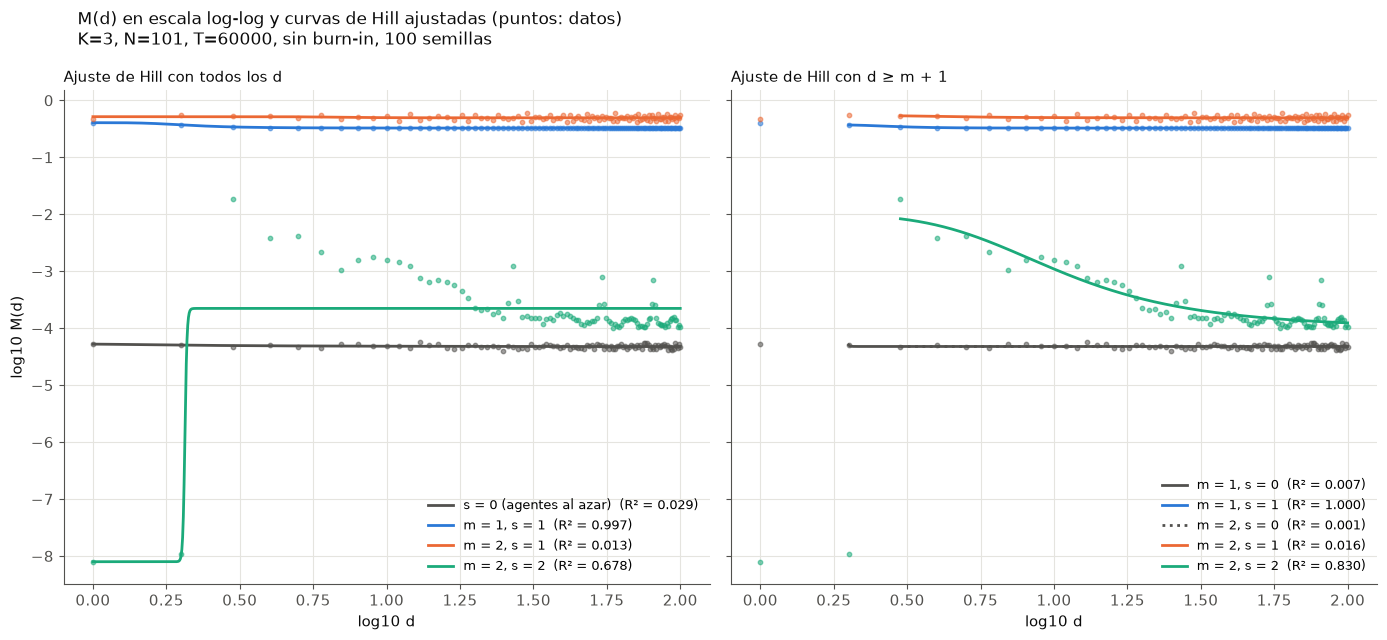

  Guardado: graficas\Fase12_parametros_hill_N101_T60000.png


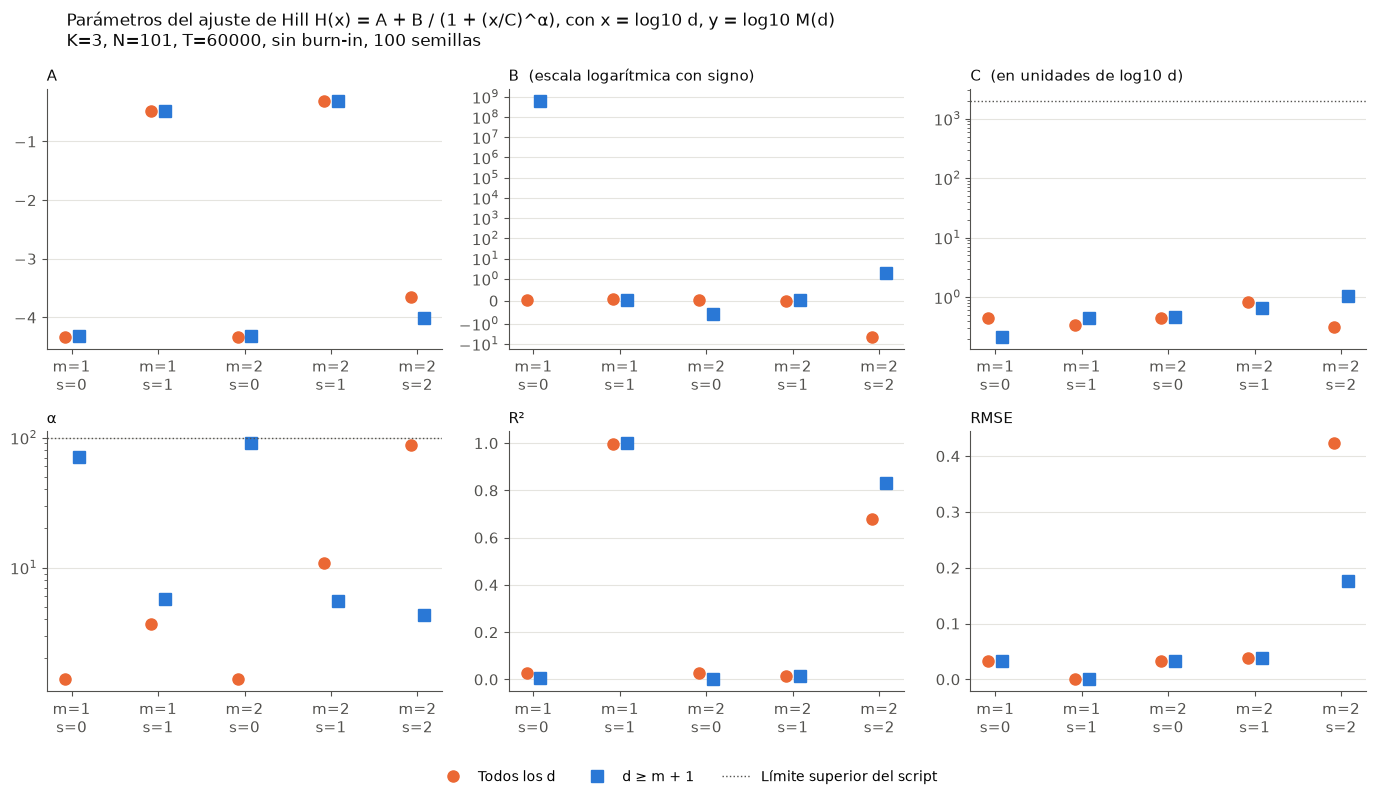


Listo. Tiempo total: 4.9 min


In [1]:
"""
FASE 12 - Ajuste de Hill a la informacion mutua M(d) en escala log-log
=====================================================================
Tesis: Complejidad e informacion en un minority game con opcion de abstencion
Encargo del Dr. Ricardo Mansilla. Base: R. Mansilla, Phys. Rev. E 62, 4553 (2000), Ec. (6)

Casos (todos con K = 3, N = 101, T = 60000, sin burn-in, 100 semillas):
    m=1, s=0   m=1, s=1   m=2, s=0   m=2, s=1   m=2, s=2

  * s = 0: los agentes no tienen estrategias y eligen al azar. La memoria m no
    se consulta, asi que m=1,s=0 y m=2,s=0 son LA MISMA serie: se simula una
    sola vez (igual que la referencia de agentes al azar de la Fase 8).
  * s = 1: cada agente tiene una sola estrategia; el puntaje no tiene efecto.
  * m=2, s=2: es el caso de la Fase 7.

Que hace este codigo:
  1. Simula los 4 conjuntos distintos de series y calcula M(d), d = 1..100,
     en cada cadena; luego promedia sobre las 100 cadenas.
  2. Comprobacion: los agentes al azar deben dar exactamente los mismos numeros
     que el CSV de la Fase 8, y m=2,s=2 los mismos que el CSV de la Fase 7.
     Si no, el notebook se detiene.
  3. Toma x = log10(d), y = log10(M(d)) (solo se quitan los puntos con M(d) = 0)
     y ajusta la funcion de Hill  H(x) = A + B / (1 + (x/C)^alfa)  con el
     script del Dr. Mansilla (ajuste_hill.py, copiado sin cambios a esta
     carpeta), dos veces por caso:
        - con todos los d = 1..100
        - solo con d >= m + 1
  4. Ademas, la recta log10 M contra log10 d (np.polyfit grado 1, todos los d),
     porque toda grafica log-log reporta pendiente y R^2.

Regla del ganador: la misma de las fases 7 y 8 (argmin sobre las 3 opciones,
contando una opcion vacia; empate -> moneda), para que los casos sean
comparables con esas fases. Se cuenta cuantos turnos tuvieron una opcion vacia.

gamma = K^m / N va en los CSV, no en los titulos.

Las funciones validar_parametros, regla_ganador, simular_con_puntaje,
informacion_mutua, simular_ingenuos, resumir y guardar_Md_todas son las de
resultados/Fase 8/Fase8_binario_variacion_m_N101.ipynb, sin cambios.
"""

import csv
import os
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t as t_student
from joblib import Parallel, delayed

# script del Dr. Mansilla, en esta misma carpeta y sin cambios
from ajuste_hill import ajustar_hill, hill


# =====================================================================
# OPCIONES
# =====================================================================
# Las graficas SIEMPRE se muestran en el notebook.
# True  = ademas se guardan como PNG en CARPETA_GRAFICAS
DESCARGAR_GRAFICAS = True

# True  = se guardan los CSV en CARPETA_CSV
GUARDAR_CSV        = True

# True = compara agentes al azar con la Fase 8 y m=2,s=2 con la Fase 7
HACER_COMPROBACION = True

CARPETA_CSV       = "csv"
CARPETA_GRAFICAS  = "graficas"
CARPETA_CSV_FASE7 = os.path.join("..", "Fase 7", "csv")   # solo se lee
CARPETA_CSV_FASE8 = os.path.join("..", "Fase 8", "csv")   # solo se lee

#   -1 -> usa TODOS los nucleos;  1 -> un solo nucleo
N_NUCLEOS = -1


# =====================================================================
# PARAMETROS
# =====================================================================
SEMILLA_MAESTRA = 1907443528
N_CADENAS = 100

N     = 101     # numero de agentes
K     = 3       # 0 = comprar, 1 = vender, 2 = abstenerse
T     = 60000   # turnos registrados, desde el primero (sin burn-in)
D_MAX = 100     # M(d) para d = 1, ..., D_MAX
NIVEL = 0.95    # nivel de confianza del intervalo

# Casos (m, s) en el orden pedido. s = 0 -> agentes al azar.
CASOS = [(1, 0), (1, 1), (2, 0), (2, 1), (2, 2)]

# Los agentes al azar llevan una memoria de 3 datos que nadie consulta
# (igual que en la Fase 8; asi las series son las mismas que alla).
M_AZAR = 3

# Ajuste de Hill: los valores por defecto del script del Dr. Mansilla
INICIOS_HILL = 30
SEMILLA_HILL = 12345
ALFA_MIN     = 0.01
ALFA_MAX     = 100.0


# =====================================================================
# NUCLEO VALIDADO  (igual que en la Fase 8)
# =====================================================================
def validar_parametros(N, K):
    """Con K = 2, N impar evita el empate entre las dos opciones.
    Con K = 3, N no multiplo de 3 evita el empate entre las tres."""
    if K == 2 and N % 2 == 0:
        raise ValueError(f"Con K = 2, N debe ser impar (N = {N})")
    if K == 3 and N % 3 == 0:
        raise ValueError(f"Con K = 3, N no debe ser multiplo de 3 (N = {N})")


def regla_ganador(conteos, rng):
    """Gana el argmin sobre las K acciones, con desempate aleatorio."""
    empatados = np.flatnonzero(conteos == conteos.min())
    return int(rng.choice(empatados))


def simular_con_puntaje(N, m, s, K, T, semilla):
    """Reglas del codigo base, sin burn-in. Cada agente usa la estrategia
    con mas puntos y, al final del ciclo, todas las estrategias que
    habrian acertado al ganador reciben un punto.

    Devuelve la serie de ganadores, cuantas veces acerto cada agente y
    cuantos agentes eligieron cada opcion en cada turno.
    """
    rng = np.random.default_rng(semilla)
    N_HIST = K ** m

    # estrategias[i, j, h] = accion que la estrategia j del agente i
    #                        recomienda ante la historia con indice h
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))

    # puntajes[i, j] = puntos virtuales (casos de exito) de esa estrategia
    puntajes = np.zeros((N, s))

    # memoria: los m datos que el mercado tiene "al nacer"
    historia = rng.integers(0, K, size=m)

    pesos = K ** np.arange(m - 1, -1, -1)   # convierte historia -> indice
    indices = np.arange(N)

    serie_ganadores = np.zeros(T, dtype=int)
    exitos_agente = np.zeros(N, dtype=int)
    conteos_por_turno = np.zeros((T, K), dtype=np.int32)

    for t in range(T):

        # 1. que situacion estan viendo los agentes
        idx = int(historia @ pesos)

        # 2. cada agente toma su estrategia con mas puntos.
        #    El ruido < 1 rompe empates al azar sin alterar el orden
        #    entre puntajes enteros distintos.
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)

        # 3. consulta esa estrategia en la historia actual y actua
        acciones = estrategias[indices, mejor, idx]

        # 4. se cuenta cuantos eligieron cada opcion
        conteos = np.bincount(acciones, minlength=K)

        # 5. gana la minoria
        ganador = regla_ganador(conteos, rng)

        # 6. se premian TODAS las estrategias que hubieran acertado,
        #    se hayan jugado o no (regla del codigo base / PRE 62).
        puntajes += (estrategias[:, :, idx] == ganador)

        # 7. registrar desde el primer ciclo
        serie_ganadores[t] = ganador
        conteos_por_turno[t] = conteos
        exitos_agente += (acciones == ganador)

        # 8. la memoria se desplaza: entra el ganador, sale el mas viejo
        historia = np.roll(historia, -1)
        historia[-1] = ganador

    return serie_ganadores, exitos_agente, conteos_por_turno


def informacion_mutua(serie, d, K):
    """M(d) = sum_{a,b} P_ab(d) * log2[ P_ab(d) / (P_a * P_b) ]

    P_ab(d): probabilidad de encontrar el simbolo a y, d lugares despues,
             el simbolo b. Se estima contando todos los pares
             (serie[i], serie[i+d]) de la cadena.
    P_a:     densidad del simbolo a en la cadena completa (como dice
             Mansilla: "the density of the symbol alpha").

    La suma corre sobre los K*K pares (a, b). Los pares que nunca
    aparecen (P_ab = 0) no aportan, porque 0 * log(0) = 0.
    """
    x = serie[:-d]          # simbolo alpha
    y = serie[d:]           # simbolo beta, d lugares despues
    n_pares = len(x)

    # probabilidades conjuntas P_ab(d): matriz K x K
    conjunta = np.bincount(x * K + y, minlength=K * K).reshape(K, K) / n_pares

    # densidades P_a de cada simbolo en toda la cadena
    densidad = np.bincount(serie, minlength=K) / len(serie)
    producto = np.outer(densidad, densidad)      # P_a * P_b

    M_d = 0.0
    for a in range(K):
        for b in range(K):
            if conjunta[a, b] > 0:
                M_d += conjunta[a, b] * np.log2(conjunta[a, b] / producto[a, b])
    return M_d


def simular_ingenuos(N, m, K, T, burn_in, semilla):
    """Corre una partida con agentes que eligen al azar.

    Cada agente, en cada ciclo, elige 0, 1 o 2 con probabilidad 1/3.
    No hay estrategias, no hay puntajes, no hay aprendizaje.

    La memoria (historia de los ultimos m ganadores) se sigue llevando
    igual que en el codigo base, para que la estructura sea la misma y
    despues solo haya que cambiar la forma de decidir. Pero aqui nadie
    la consulta.
    """
    rng = np.random.default_rng(semilla)

    historia = rng.integers(0, K, size=m)
    serie_ganadores = np.zeros(T, dtype=int)

    for t in range(burn_in + T):

        # 1. cada agente elige al azar entre 0, 1 y 2
        acciones = rng.integers(0, K, size=N)

        # 2. se cuenta cuantos eligieron cada opcion
        conteos = np.bincount(acciones, minlength=K)

        # 3. gana la minoria (misma regla que el codigo base)
        ganador = regla_ganador(conteos, rng)

        # 4. registrar solo despues del transitorio
        if t >= burn_in:
            serie_ganadores[t - burn_in] = ganador

        # 5. la memoria se desplaza: entra el ganador, sale el mas viejo
        historia = np.roll(historia, -1)
        historia[-1] = ganador

    return serie_ganadores


def resumir(tabla, t_crit):
    """Promedio sobre las cadenas (filas), con su intervalo de confianza."""
    media = tabla.mean(axis=0)
    desv = tabla.std(axis=0, ddof=1)
    error_est = desv / np.sqrt(tabla.shape[0])
    return {"media": media, "desv": desv, "error_est": error_est,
            "ic_inf": media - t_crit * error_est,
            "ic_sup": media + t_crit * error_est}


def guardar_Md_todas(ruta, tabla, semillas, encabezado):
    """Mismo formato que los CSV de las fases 2 y 3."""
    distancias = np.arange(1, tabla.shape[1] + 1)
    np.savetxt(ruta, np.column_stack([np.asarray(semillas).astype(np.int64), tabla]),
               fmt=["%d"] + ["%.8e"] * tabla.shape[1], delimiter=",",
               header=(encabezado + "\nsemilla,"
                       + ",".join(f"d{d}" for d in distancias)),
               comments="# ")


# =====================================================================
# SIMULACION
# =====================================================================
def cadena_estrategias(m, s, semilla):
    """Una partida con s estrategias por agente y puntaje."""
    serie, exitos, conteos = simular_con_puntaje(N, m, s, K, T, int(semilla))
    Md = np.array([informacion_mutua(serie, d, K) for d in range(1, D_MAX + 1)])
    vacias = int((conteos == 0).any(axis=1).sum())
    return Md, np.bincount(serie, minlength=K) / T, exitos.sum() / (N * T), vacias


def cadena_azar(semilla):
    """Una partida de agentes que eligen al azar (s = 0)."""
    serie = simular_ingenuos(N, M_AZAR, K, T, 0, int(semilla))
    Md = np.array([informacion_mutua(serie, d, K) for d in range(1, D_MAX + 1)])
    return Md, np.bincount(serie, minlength=K) / T, np.nan, -1


def correr(m, s, semillas):
    """Todas las cadenas de un conjunto. El resultado no depende del numero de
    nucleos: cada cadena usa solo su semilla y joblib respeta el orden."""
    validar_parametros(N, K)
    if s == 0:
        tareas = (delayed(cadena_azar)(int(sem)) for sem in semillas)
    else:
        tareas = (delayed(cadena_estrategias)(m, s, int(sem)) for sem in semillas)
    if N_NUCLEOS == 1:
        bloque = [f(*a, **k) for f, a, k in tareas]
    else:
        bloque = Parallel(n_jobs=N_NUCLEOS)(tareas)
    return {"Md": np.array([b[0] for b in bloque]),
            "frec": np.array([b[1] for b in bloque]),
            "exito": np.array([b[2] for b in bloque]),
            "vacias": np.array([b[3] for b in bloque])}


def redondear(tabla):
    """Los mismos numeros que quedan escritos en un CSV con formato %.8e."""
    return np.array([[float(f"{v:.8e}") for v in fila] for fila in tabla])


def comprobar(nombre, tabla, semillas, ruta_ref):
    """Compara M(d) de cada cadena con el CSV de una fase anterior."""
    ref = np.loadtxt(ruta_ref, delimiter=",", comments="#")[:len(semillas)]
    iguales = (np.array_equal(ref[:, 0].astype(np.int64), np.asarray(semillas).astype(np.int64))
               and np.array_equal(ref[:, 1:], redondear(tabla)))
    print(f"  COMPROBACION {nombre}: M(d) de las {len(semillas)} cadenas identica al CSV "
          f"{os.path.basename(ruta_ref)}: {iguales}", flush=True)
    if not iguales:
        raise RuntimeError(f"COMPROBACION FALLIDA ({nombre}). El notebook se detiene aqui.")


# =====================================================================
# AJUSTES
# =====================================================================
def puntos_loglog(d, Md, d_min):
    """x = log10 d, y = log10 M(d), con d >= d_min y sin los puntos M(d) = 0."""
    sel = (d >= d_min) & (Md > 0)
    return np.log10(d[sel]), np.log10(Md[sel])


def ajuste_hill(d, Md, d_min):
    x, y = puntos_loglog(d, Md, d_min)
    r = ajustar_hill(x, y, INICIOS_HILL, SEMILLA_HILL, ALFA_MIN, ALFA_MAX)
    return {"x": x, "y": y, "r": r, "d_min": d_min}


def d_C(C):
    """Distancia d donde la curva de Hill va a la mitad: 10^C (inf si C es enorme)."""
    with np.errstate(over="ignore"):
        return float(np.power(10.0, C))


def ajuste_recta(d, Md):
    x, y = puntos_loglog(d, Md, 1)
    p = np.polyfit(x, y, 1)
    R2 = 1 - np.sum((y - np.polyval(p, x)) ** 2) / np.sum((y - y.mean()) ** 2)
    return {"x": x, "pendiente": p[0], "ordenada": p[1], "R2": R2}


# =====================================================================
# GRAFICAS
# =====================================================================
GRIS = "#52514e"
GRIS_CLARO = "#9a9893"
TINTA = "#0b0b0b"
NARANJA = "#eb6834"
AZUL = "#2a78d6"
COLOR_CASO = {"azar": GRIS, (1, 1): AZUL, (2, 1): NARANJA, (2, 2): "#1baa7a"}
SUBTITULO = f"K={K}, N={N}, T={T}, sin burn-in, {N_CADENAS} semillas"


def clave_datos(m, s):
    return "azar" if s == 0 else (m, s)


def nombre_caso(m, s):
    return f"m = {m}, s = {s}" + ("  (agentes al azar)" if s == 0 else "")


def texto_hill(r):
    c = r["coeficientes"]
    return (f"A = {c['A']:.3f}, B = {c['B']:.3f}, C = {c['C']:.3f}, α = {c['alfa']:.3g}\n"
            f"R² = {r['R2']:.4f}, RMSE = {r['RMSE']:.3g}")


def terminar_figura(fig, archivo):
    if DESCARGAR_GRAFICAS:
        ruta = os.path.join(CARPETA_GRAFICAS, archivo)
        fig.savefig(ruta, dpi=150)
        print(f"  Guardado: {ruta}", flush=True)
    plt.show()
    plt.close(fig)


def graficar_caso(m, s, d, res, ajustes, recta, ref_azar):
    fig = plt.figure(figsize=(14, 8.5))
    gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.25], hspace=0.35, wspace=0.22)
    ax_lin = fig.add_subplot(gs[:, 0])
    ax_log = fig.add_subplot(gs[:3, 1])
    ax_res = fig.add_subplot(gs[3, 1], sharex=ax_log)

    # --- M(d) contra d ---
    ax_lin.plot(d, res["media"], color=AZUL, lw=1.4, marker="o", ms=3,
                label="Promedio de las cadenas")
    ax_lin.fill_between(d, res["ic_inf"], res["ic_sup"], color=AZUL, alpha=0.2, lw=0,
                        label=f"Intervalo de confianza {int(NIVEL * 100)} %")
    if s > 0:
        ax_lin.plot(d, ref_azar, color=GRIS, lw=1.3, ls="--", label="Agentes al azar")
    ax_lin.set_xlabel("Distancia d")
    ax_lin.set_ylabel("M(d)  [bits]")
    ax_lin.set_title("Información mutua", loc="left", color=TINTA, fontsize=11)
    ax_lin.set_xlim(0, D_MAX + 1)
    ax_lin.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax_lin.grid(axis="y", color="#e5e4df", lw=0.8)
    ax_lin.legend(frameon=False, fontsize=9)

    # --- log-log con los ajustes ---
    x_todos = ajustes["todos"]["x"]
    ax_log.scatter(x_todos, ajustes["todos"]["y"], s=14, color=TINTA, zorder=3,
                   label="log10 M(d)")
    estilos = {"todos": (NARANJA, "-", "o", "Hill con todos los d"),
               "desde": (AZUL, "--", "s", f"Hill con d ≥ {m + 1}")}
    for clave, (color, ls, marca, etiqueta) in estilos.items():
        a = ajustes[clave]
        xx = np.linspace(a["x"].min(), a["x"].max(), 800)
        ax_log.plot(xx, hill(xx, **a["r"]["coeficientes"]), color=color, lw=2, ls=ls,
                    label=f"{etiqueta}:\n{texto_hill(a['r'])}")
        ax_res.scatter(a["x"], a["y"] - hill(a["x"], **a["r"]["coeficientes"]), s=10,
                       color=color, marker=marca, label=etiqueta)
    xr = np.array([recta["x"].min(), recta["x"].max()])
    ax_log.plot(xr, recta["ordenada"] + recta["pendiente"] * xr, color=GRIS_CLARO, lw=1.5,
                ls=":", label=(f"Recta con todos los d:\npendiente = {recta['pendiente']:.4f},"
                               f" R² = {recta['R2']:.4f}"))
    ax_log.set_ylabel("log10 M(d)")
    ax_log.set_title("Escala log-log y ajustes", loc="left", color=TINTA, fontsize=11)
    ax_log.grid(color="#e5e4df", lw=0.8)
    ax_log.legend(frameon=False, fontsize=8.5, loc="best")
    plt.setp(ax_log.get_xticklabels(), visible=False)
    ax_res.axhline(0, color=GRIS, lw=1)
    ax_res.set_xlabel("log10 d")
    ax_res.set_ylabel("Residuo")
    ax_res.grid(color="#e5e4df", lw=0.8)

    fig.suptitle(f"M(d) y ajuste de Hill — {nombre_caso(m, s)}\n" + SUBTITULO,
                 x=0.06, ha="left", color=TINTA, fontsize=12)
    fig.subplots_adjust(top=0.88, bottom=0.08, left=0.06, right=0.98)
    terminar_figura(fig, f"Fase12_Md_hill_N{N}_m{m}_s{s}_T{T}.png")


def graficar_comparacion(d, resultados, ajustes):
    fig, ejes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
    for ax, clave_aj, titulo in ((ejes[0], "todos", "Ajuste de Hill con todos los d"),
                                 (ejes[1], "desde", "Ajuste de Hill con d ≥ m + 1")):
        dibujados = set()
        for (m, s) in CASOS:
            cd = clave_datos(m, s)
            color = COLOR_CASO[cd]
            a = ajustes[(m, s)][clave_aj]
            if cd not in dibujados:
                x, y = puntos_loglog(d, resultados[cd]["media"], 1)
                ax.scatter(x, y, s=10, color=color, alpha=0.55, zorder=3)
                dibujados.add(cd)
            if s == 0 and clave_aj == "todos" and m != CASOS[0][0]:
                continue   # con todos los d, los dos casos s = 0 son el mismo ajuste
            etiqueta = ("s = 0 (agentes al azar)" if (s == 0 and clave_aj == "todos")
                        else nombre_caso(m, s).replace("  (agentes al azar)", ""))
            ls = ":" if (s == 0 and m == 2 and clave_aj == "desde") else "-"
            xx = np.linspace(a["x"].min(), a["x"].max(), 800)
            ax.plot(xx, hill(xx, **a["r"]["coeficientes"]), color=color, lw=2, ls=ls,
                    label=f"{etiqueta}  (R² = {a['r']['R2']:.3f})")
        ax.set_xlabel("log10 d")
        ax.set_title(titulo, loc="left", color=TINTA, fontsize=11)
        ax.grid(color="#e5e4df", lw=0.8)
        ax.legend(frameon=False, fontsize=9, loc="lower right")
    ejes[0].set_ylabel("log10 M(d)")
    fig.suptitle("M(d) en escala log-log y curvas de Hill ajustadas (puntos: datos)\n"
                 + SUBTITULO, x=0.06, ha="left", color=TINTA, fontsize=12)
    fig.tight_layout()
    terminar_figura(fig, f"Fase12_comparacion_hill_N{N}_T{T}.png")


def graficar_parametros(ajustes):
    pos = np.arange(len(CASOS))
    etiquetas = [f"m={m}\ns={s}" for m, s in CASOS]
    # escala: None = lineal, "log" = logaritmica, "symlog" = logaritmica con signo
    #         (B puede ser negativo y, en ajustes que no convergen bien, enorme)
    medidas = [("A", "A", None), ("B", "B  (escala logarítmica con signo)", "symlog"),
               ("C", "C  (en unidades de log10 d)", "log"),
               ("alfa", "α", "log"), ("R2", "R²", None), ("RMSE", "RMSE", None)]
    limites = {"alfa": ALFA_MAX, "C": np.log10(D_MAX) * 1000}   # limites superiores del script
    fig, ejes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, (clave, titulo, log) in zip(ejes.ravel(), medidas):
        for clave_aj, color, marca, desplaz, etq in (("todos", NARANJA, "o", -0.08, "Todos los d"),
                                                     ("desde", AZUL, "s", 0.08, "d ≥ m + 1")):
            v = []
            for caso in CASOS:
                r = ajustes[caso][clave_aj]["r"]
                v.append(r["coeficientes"][clave] if clave in r["coeficientes"] else r[clave])
            ax.plot(pos + desplaz, v, ls="none", marker=marca, ms=8, color=color, label=etq)
        if log == "symlog":
            ax.set_yscale("symlog", linthresh=1)
        elif log == "log":
            ax.set_yscale("log")
        if clave in limites:
            ax.axhline(limites[clave], color=GRIS, lw=1, ls=":", label="Límite superior del script")
        ax.set_xticks(pos)
        ax.set_xticklabels(etiquetas)
        ax.set_title(titulo, loc="left", color=TINTA, fontsize=11)
        ax.grid(axis="y", color="#e5e4df", lw=0.8)
    m_alfa, n_alfa = ejes[1, 0].get_legend_handles_labels()   # el panel de alfa
    fig.legend(m_alfa, n_alfa, frameon=False, loc="lower center", ncol=3, fontsize=10)
    fig.suptitle("Parámetros del ajuste de Hill H(x) = A + B / (1 + (x/C)^α), con x = log10 d,"
                 " y = log10 M(d)\n" + SUBTITULO, x=0.06, ha="left", color=TINTA, fontsize=12)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    terminar_figura(fig, f"Fase12_parametros_hill_N{N}_T{T}.png")


# =====================================================================
# PROGRAMA PRINCIPAL
# =====================================================================
if __name__ == "__main__":
    inicio = time.time()
    semillas = np.random.SeedSequence(SEMILLA_MAESTRA).generate_state(N_CADENAS)
    d = np.arange(1, D_MAX + 1)
    t_crit = t_student.ppf(0.5 + NIVEL / 2, N_CADENAS - 1)
    if GUARDAR_CSV:
        os.makedirs(CARPETA_CSV, exist_ok=True)
    if DESCARGAR_GRAFICAS:
        os.makedirs(CARPETA_GRAFICAS, exist_ok=True)
    plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRIS, "axes.labelcolor": TINTA,
                         "xtick.color": GRIS, "ytick.color": GRIS,
                         "axes.spines.top": False, "axes.spines.right": False})

    # --- 1. simulaciones: 4 conjuntos distintos de series ---
    print(f"FASE 12: K={K}, N={N}, T={T}, {N_CADENAS} cadenas, semilla maestra {SEMILLA_MAESTRA}\n",
          flush=True)
    resultados = {}
    conjuntos = [("azar", 0, 0)] + [((m, s), m, s) for m, s in CASOS if s > 0]
    for cd, m, s in conjuntos:
        t0 = time.time()
        datos = correr(m, s, semillas)
        r = resumir(datos["Md"], t_crit)
        resultados[cd] = r
        frec = datos["frec"].mean(axis=0)
        if s == 0:
            base = f"agentes_al_azar_K{K}_N{N}_T{T}"
            parametros = f"agentes al azar (s=0) N={N} K={K} T={T} burn_in=0"
            gamma = np.nan
            extra = "tasa de exito: no se mide  turnos con opcion vacia: no se cuentan"
        else:
            base = f"con_puntaje_N{N}_m{m}_s{s}_T{T}"
            gamma = K ** m / N
            parametros = f"N={N} m={m} s={s} K={K} T={T} burn_in=0 gamma={gamma:.6f} con_puntaje"
            extra = (f"tasa de exito={datos['exito'].mean():.4f}  "
                     f"turnos con opcion vacia={int(datos['vacias'].sum())} de {N_CADENAS * T}")
        d_max = int(d[np.argmax(r["media"])])
        print(f"{'s=0 (azar)' if s == 0 else f'm={m}, s={s}':<11} frec(0,1,2)=({frec[0]:.4f}, "
              f"{frec[1]:.4f}, {frec[2]:.4f})  M(1)={r['media'][0]:.3e}  M(2)={r['media'][1]:.3e}  "
              f"M(3)={r['media'][2]:.3e}  M_max={r['media'].max():.3e} (d={d_max})  "
              f"M(d)=0 en {int((r['media'] == 0).sum())} distancias  {extra}  "
              f"[{time.time() - t0:.0f} s]", flush=True)

        if HACER_COMPROBACION and s == 0:
            comprobar("agentes al azar vs Fase 8", datos["Md"], semillas, os.path.join(
                CARPETA_CSV_FASE8, f"Fase8_Md_agentes_al_azar_K{K}_N{N}_T{T}_todas_las_cadenas.csv"))
        if HACER_COMPROBACION and (m, s) == (2, 2):
            comprobar("m=2, s=2 vs Fase 7", datos["Md"], semillas, os.path.join(
                CARPETA_CSV_FASE7, f"Fase7_Md_con_puntaje_N{N}_m2_s2_T{T}_todas_las_cadenas.csv"))

        if GUARDAR_CSV:
            np.savetxt(os.path.join(CARPETA_CSV, f"Fase12_Md_{base}_promedio.csv"),
                       np.column_stack([d, r["media"], r["desv"], r["error_est"], r["ic_inf"],
                                        r["ic_sup"], np.full(D_MAX, gamma)]),
                       fmt=["%d"] + ["%.8e"] * 6, delimiter=",", comments="# ",
                       header=(f"FASE 12. M(d) promedio, Ec. (6) PRE 62, bits\n{parametros} "
                               f"cadenas={N_CADENAS} semilla_maestra={SEMILLA_MAESTRA}\n"
                               f"intervalo de confianza {int(NIVEL * 100)}% con t de Student "
                               f"(t={t_crit:.4f}); gamma = nan cuando s = 0 (m no se usa)\n"
                               "d,media,desv_estandar,error_estandar,ic_inferior,ic_superior,gamma"))
            guardar_Md_todas(os.path.join(CARPETA_CSV, f"Fase12_Md_{base}_todas_las_cadenas.csv"),
                             datos["Md"], semillas,
                             f"FASE 12. M(d) de cada cadena. Fila = una semilla, columna = d\n"
                             f"{parametros}")

    # --- 2. ajustes ---
    print("\nAjustes (x = log10 d, y = log10 M(d)):", flush=True)
    ajustes, filas = {}, []
    for m, s in CASOS:
        media = resultados[clave_datos(m, s)]["media"]
        aj = {"todos": ajuste_hill(d, media, 1), "desde": ajuste_hill(d, media, m + 1)}
        recta = ajuste_recta(d, media)
        ajustes[(m, s)] = aj
        ajustes[(m, s)]["recta"] = recta
        for clave_aj, rango in (("todos", "todos_los_d"), ("desde", "d_desde_m_mas_1")):
            r = aj[clave_aj]["r"]
            c = r["coeficientes"]
            avisos = r["avisos"]
            limite = int(any("límite" in a for a in avisos))
            debil = int(any("débilmente" in a for a in avisos))
            print(f"  {nombre_caso(m, s):<32} {rango:<16} n={r['n']:3d}  A={c['A']:9.4f}  "
                  f"B={c['B']:9.4f}  C={c['C']:8.4f}  alfa={c['alfa']:9.4f}  R2={r['R2']:.4f}  "
                  f"RMSE={r['RMSE']:.4f}  convergentes={r['inicios_convergentes']}/{r['inicios']}"
                  f"  aviso_limite={limite}  aviso_debil={debil}", flush=True)
            filas.append([m, s, f"{(K ** m / N):.6f}", rango, aj[clave_aj]["d_min"], r["n"],
                          f"{c['A']:.8e}", f"{c['B']:.8e}", f"{c['C']:.8e}", f"{d_C(c['C']):.8e}",
                          f"{c['alfa']:.8e}", f"{r['R2']:.8f}", f"{r['RMSE']:.8e}",
                          f"{r['SSE']:.8e}", r["inicios_convergentes"], r["inicios"],
                          f"{r['condicion_jacobiano_normalizado']:.4e}"
                          if r["condicion_jacobiano_normalizado"] is not None else "inf",
                          limite, debil, f"{recta['pendiente']:.8f}", f"{recta['R2']:.8f}"])
        print(f"  {nombre_caso(m, s):<32} recta (todos los d): pendiente={recta['pendiente']:.4f}"
              f"  R2={recta['R2']:.4f}", flush=True)

    if GUARDAR_CSV:
        ruta = os.path.join(CARPETA_CSV, f"Fase12_ajustes_hill_N{N}_T{T}.csv")
        with open(ruta, "w", newline="", encoding="utf-8") as f:
            f.write(f"# FASE 12. Ajuste de Hill H(x) = A + B/(1+(x/C)^alfa) con x = log10 d, "
                    f"y = log10 M(d). K={K} N={N} T={T} cadenas={N_CADENAS} "
                    f"semilla_maestra={SEMILLA_MAESTRA}\n")
            f.write(f"# script ajuste_hill.py (Dr. Mansilla), inicios={INICIOS_HILL} "
                    f"semilla={SEMILLA_HILL} alfa en [{ALFA_MIN}, {ALFA_MAX}]. Solo se quitan "
                    f"los puntos con M(d)=0. d_C = 10^C. s=0: agentes al azar.\n")
            f.write("# aviso_limite=1: C o alfa quedo junto a un limite de busqueda. aviso_debil=1:"
                    " parametros debilmente identificados. pendiente_recta y R2_recta: "
                    "np.polyfit grado 1 con todos los d\n")
            escritor = csv.writer(f)
            escritor.writerow(["m", "s", "gamma", "rango", "d_min", "n_puntos", "A", "B", "C",
                               "d_C", "alfa", "R2", "RMSE", "SSE", "inicios_convergentes",
                               "inicios", "condicion_jacobiano", "aviso_limite", "aviso_debil",
                               "pendiente_recta", "R2_recta"])
            escritor.writerows(filas)
        print(f"\nGuardado: {ruta}")

    # --- 3. graficas ---
    print("\nGraficas:")
    for m, s in CASOS:
        graficar_caso(m, s, d, resultados[clave_datos(m, s)], ajustes[(m, s)],
                      ajustes[(m, s)]["recta"], resultados["azar"]["media"])
    graficar_comparacion(d, resultados, ajustes)
    graficar_parametros(ajustes)

    print(f"\nListo. Tiempo total: {(time.time() - inicio) / 60:.1f} min")
